In [2]:
import torch 
import torch.nn as nn
import math
import typing
from typing import List, Union
import pandas as pd
import torch.nn.functional as F
import numpy as np
from datetime import datetime
import matplotlib.pyplot as plt

In [3]:
def split_train_test(tensor: torch.Tensor, train_percent: float):
    """
    Divide um tensor em treino e teste, garantindo que os índices sejam inteiros.
    """
    assert isinstance(train_percent, float), "train_percent deve ser um número decimal entre 0 e 1."
    assert 0.0 < train_percent < 1.0, "O percentual de treino deve estar entre 0 e 1."

    num_train = int(round(len(tensor) * train_percent))  # Conversão segura para inteiro

    indices = torch.randperm(len(tensor))  # Embaralha os índices
    train_indices, test_indices = indices[:num_train], indices[num_train:]  # Separa treino e teste

    return tensor[train_indices], tensor[test_indices]

def custom_dataloader(dataset, batch_size, context_len, device,):
        # Verifique o tamanho total do dataset
    dataset_size = len(dataset)
    # print('dataset is on ', dataset.data.get_device())
    max_iter = dataset_size // batch_size
    print(max_iter, 'expected iters with size', batch_size)
    def generator():
        for _ in range(max_iter): 
            # Gere n índices aleatórios no intervalo permitido
            ix = torch.randint(dataset_size - context_len -1, (batch_size,))
            x = torch.stack([dataset[i:i+context_len] for i in ix])
            y = torch.stack([dataset[i+1:i+context_len+1] for i in ix])

            # x, y = x.to(device), y.to(device)

            yield x, y
        
    return generator()

def one_hot_encoding(token_ids: torch.Tensor, vocab_size: int):
    """
    Cria uma matriz de one-hot encoding para múltiplos token_ids.

    Args:
        token_ids (torch.Tensor): Tensor 1D contendo os índices dos tokens a serem marcados com 1.
        vocab_size (int): Número total de posições possíveis.

    Returns:
        torch.Tensor: Matriz de shape (len(token_ids), vocab_size) onde cada linha é um vetor one-hot.
    """
    batch_size = token_ids.shape[0]
    one_hot_matrix = torch.zeros((batch_size, vocab_size), dtype=torch.float32)
    one_hot_matrix[torch.arange(batch_size), token_ids] = 1.0  # Define 1 nas posições dos token_ids
    return one_hot_matrix

class PositionStateTokenizer(nn.Module):
    def __init__(self, positions: List[str], vocab_size:int) -> None:
        super().__init__()
        self.positions = positions.copy()
        assert vocab_size == len(set(positions))
        self.vocab_size = len(set(positions))
        self.string_to_id = {p:i for i, p in enumerate(positions)}
        self.id_to_string = {i:p for i, p in enumerate(positions)}

    def forward(self, x: List[str], get_tensor: bool=True) -> Union[torch.tensor, list]:
        if get_tensor:
            return torch.tensor([self.string_to_id[p] for p in x], dtype=torch.long)
        else:
            return [self.string_to_id[p] for p in x]
    def reverse(self, x: List[int]) -> list:
        return [self.id_to_string[i] for i in x]

class InputEmbeddings(nn.Module):
    def __init__(self, vocab_size: int, d_model:int,) -> None:
        super().__init__()
        self.vocab_size = vocab_size
        self.d_model = d_model
        self.embedding = nn.Embedding(num_embeddings=vocab_size, embedding_dim=d_model)
    def forward(self, x):
        return self.embedding(x) * math.sqrt(self.d_model)
    
class PositionalEncoding(nn.Module):
    def __init__(self, d_model: int, max_seq_length: int) -> None:
        super().__init__()
        self.d_model = d_model
        self.max_seq_length = max_seq_length

        pe = torch.zeros(max_seq_length, d_model)
        position = torch.arange(0, max_seq_length, dtype=torch.float).unsqueeze(1)
        div_term = torch.exp(torch.arange(0, d_model, 2, dtype=torch.float) * -(math.log(10_000)/d_model))

        pe[:, 0::2] = torch.sin(position * div_term) # even positions
        pe[:, 1::2] = torch.cos(position * div_term) # odd positions

        self.register_buffer('pe', pe.unsqueeze(0))
    
    def forward(self, x:torch.tensor) -> torch.tensor:
        return x + self.pe[:, :x.size(1)]
    
class AttentionHead(nn.Module):
    def __init__(self, head_dim: int) -> None:
        super().__init__()
        self.head_dim = head_dim

        # k, q, v
        self.key = nn.Linear(head_dim, head_dim, bias=False)
        self.query = nn.Linear(head_dim, head_dim, bias=False)
        self.value = nn.Linear(head_dim, head_dim, bias=False)
    
    def linear_projection(self, keys, queries, values) -> Union[torch.tensor, torch.tensor, torch.tensor]:
        return self.key(keys), self.query(queries), self.value(values)
    
    def compute_attention(self, k, q, v, mask:Union[torch.tensor, None]) -> torch.tensor:
        attention_scores = q @ k.transpose(-2, -1) / (self.head_dim**0.5)

        if mask is not None:
            attention_scores = attention_scores.masked_fill(mask == 0, float('-inf'))
        attention_weights = F.softmax(attention_scores, dim=-1)
        output = attention_weights @ v
        return output

    def forward(self, keys, queries, values, mask:Union[torch.tensor, None] = None) -> torch.tensor:
        k, q, v = self.linear_projection(keys, queries, values)
        return self.compute_attention(k, q, v, mask)

class MultiHeadAttention(nn.Module):
    def __init__(self, d_model: int, num_heads: int) -> None:
        super().__init__()
        assert d_model % num_heads == 0
        self.num_heads = num_heads
        self.d_model = d_model
        self.head_dim = d_model // num_heads
        self.heads = nn.ModuleList(
            [AttentionHead(self.d_model) for _ in range(num_heads)]
        )
        self.output_layer = nn.Linear(d_model, d_model, bias=False)
    
    def forward(self, keys, queries, values, mask:Union[torch.tensor, None] = None) -> torch.tensor:
        output = []
        for i, h in enumerate(self.heads):
            k, q, v = h.linear_projection( keys, queries, values,)
            splited_k = k[:, :, i*self.head_dim:(i+1)*self.head_dim]
            splited_q = q[:, :, i*self.head_dim:(i+1)*self.head_dim]        
            splited_v = v[:, :, i*self.head_dim:(i+1)*self.head_dim]
            head_output = h.compute_attention(splited_k, splited_q, splited_v, mask)
            # print('i', i, splited_k.shape, head_output.shape)
            output.append(head_output)
        # lin_projs [b, h, seq, d_model]
        output = torch.cat([out for out in output], dim=-1)
        output = self.output_layer(output)
        return output

class FeedForwardLayer(nn.Module):
    def __init__(self, d_model: int, d_ff: int ) -> None:
        super().__init__()
        self.d_model = d_model
        self.d_ff = d_ff
        self.linear1 = nn.Linear(d_model, d_ff)
        self.linear2 = nn.Linear(d_ff, d_model)
        self.activation_layer = nn.ReLU()
    
    def forward(self, x) -> torch.tensor:
        x = self.linear1(x)
        x = self.activation_layer(x)
        x = self.linear2(x)
        return x

class DecoderTransformerBody(nn.Module):
    def __init__(self, d_model: int, num_heads: int, d_ff: int, context_len: int, dropout: float):
        super().__init__()
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_ff = d_ff
        self.context_len = context_len
        self.dropout = nn.Dropout(dropout)
        self.norm_layer1 = nn.LayerNorm(normalized_shape=d_model)
        self.norm_layer2 = nn.LayerNorm(normalized_shape=d_model)
        self.mhsa = MultiHeadAttention(d_model=d_model, num_heads=num_heads)
        self.ffwd = FeedForwardLayer(d_model=d_model, d_ff=d_ff)

        # tril
        self.register_buffer('tril', torch.tril(torch.ones(self.context_len, self.context_len)))

    def forward(self, x) -> torch.tensor:
        # decoder mask 
        mask = self.tril[:self.context_len, :self.context_len]

        # sublayer mhsa
        att_weigths = self.mhsa(x, x , x, mask)
        att_weigths = self.dropout(x + att_weigths)
        # first norm
        out = self.norm_layer1(att_weigths)

        # sublayer ffwd
        out = self.ffwd(out)
        
        out = self.dropout(x + out)
        # second norm
        out = self.norm_layer2(out)

        return out
    
class DecoderTransformerHead(nn.Module):
    def __init__(self, d_model: int, vocab_size: int):
        super().__init__()
        self.d_model = d_model
        self.vocab_size = vocab_size
        self.linear_vocab = nn.Linear(d_model, vocab_size)

    def forward(self, x, generate) -> torch.tensor:
        x = self.linear_vocab(x) # logits
        if generate:
            return F.softmax(x, dim=-1)
        else:
            return x

class DecoderTransformer(nn.Module):
    def __init__(self
                 , blocks: int
                 , d_model: int
                 , num_heads: int
                 , d_ff: int
                 , context_len: int
                 , dropout:float
                 , vocab_size: int):
        super().__init__()
        self.blocks = blocks
        self.d_model = d_model
        self.num_heads = num_heads
        self.d_ff = d_ff
        self.context_len = context_len
        self.dropout = dropout
        self.vocab_size = vocab_size
        # toekn embedding
        self.embedding = InputEmbeddings(
            vocab_size=vocab_size, d_model=d_model
        )
        # positional encoding
        self.pos_enc = PositionalEncoding(
            d_model=d_model, max_seq_length=context_len
        )
        # net architecture
        self.decoder_blocks = nn.ModuleList([DecoderTransformerBody(
            d_model=self.d_model,
            num_heads=self.num_heads,
            d_ff=self.d_ff,
            context_len=self.context_len,
            dropout=self.dropout
        ) for _ in range(self.blocks)])

        self.net = nn.Sequential(*self.decoder_blocks)
        self.decoder_head = DecoderTransformerHead(d_model=self.d_model, vocab_size=self.vocab_size)

    def forward(self, x, generate: bool ):
        # x = self.tokenizer(x)
        x = self.embedding(x)
        x = self.pos_enc(x)
        x = self.net(x)
        # probs in vocab_size space
        out = self.decoder_head(x, generate)
        return out

In [4]:
df = pd.read_csv(r'df_trainset_v0.csv')
print(df.shape)
df.head(2)

(8690, 12)


,t,pos,distance_travelled,vel,rot_vel,head_direction,position_state,encode_position_state,position_state_id,normalized_position_state_id,last_position_state_id,change_of_position_state
0,0.05,"[0.9481359873429684, 0.33197961175786933]",0.002769,"[0.05478942838579304, -0.008028506825109583]",-2.588245,"[0.998248480520846, -0.05916055390056853]",JUSISZHZYBKOLQVLLOCAAJECMBKL,[[0.75863461 0.78054116 0.05602303 0.7335959 ...,2043,0.412311,NaN,1
1,0.55,"[0.9583626153133962, 0.31473816173083613]",0.029473,"[-0.037931302661557975, -0.04846669295025419]",-6.319246,"[-0.06967333450757067, -0.9975698604401579]",JUSISZHZYBKOLOCALQVLAJECMBKL,[[0.75863461 0.78054116 0.05602303 0.12314067 ...,2035,0.410696,2043.0,1


In [5]:
positions = df['position_state'].values
unique_positions = df['position_state'].unique()

len(positions), len(unique_positions)

(8690, 4955)

In [6]:
# PARAMETERS
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('device: ', DEVICE)
VOCAB_SIZE = df['position_state_id'].nunique()
D_MODEL = 512
MAX_SEQ_LEN = 64
NUM_HEADS = 4
D_FF = D_MODEL
DROPOUT = 0.3
NUM_DECODER_BLOCKS = 1
BATCH_SIZE = 32
NUM_EPOCHS = 3
LEARNING_RATE = 1e-4

device:  cpu


In [7]:
model = DecoderTransformer(
        blocks=NUM_DECODER_BLOCKS,
        d_model=D_MODEL,
        num_heads=NUM_HEADS,
        d_ff=D_FF,
        context_len=MAX_SEQ_LEN,
        dropout=DROPOUT,
        vocab_size=VOCAB_SIZE
    )

In [8]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
loss_func = nn.CrossEntropyLoss()

In [9]:
dataset_tensor = torch.tensor(df['position_state_id'].values, dtype=torch.long)
# dataset_val = dataset_tensor[int(0.9*len(dataset_tensor)):]
# dataset_tensor = dataset_tensor[:int(0.9*len(dataset_tensor))]

# print(len(dataset_tensor), len(dataset_val))

In [10]:
train_tensor, test_tensor = split_train_test(dataset_tensor, 0.9)  # 80% treino, 20% teste

print(f"Tamanho do treino: {train_tensor.shape[0]}")
print(f"Tamanho do teste: {test_tensor.shape[0]}")

Tamanho do treino: 7821
Tamanho do teste: 869


In [11]:
loss_list = []
for epoch in range(int(NUM_EPOCHS)):
    model.train()
    epoch_loss = 0
    counter = 1
    dataloader = custom_dataloader(
                    dataset = train_tensor
                    ,batch_size = BATCH_SIZE
                    ,context_len = MAX_SEQ_LEN
                    , device = DEVICE
                    )
    epoch_loss_list = []
    

    for xb, yb in dataloader:
        optimizer.zero_grad(set_to_none=True)
        predictions = model(xb, generate=False)
        loss = loss_func(predictions.view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), yb.view(BATCH_SIZE*MAX_SEQ_LEN))
        epoch_loss_list.append(loss.detach().numpy())
        loss.backward()
        optimizer.step()
    # if epoch%(NUM_EPOCHS/10)==0:
    loss_list.append(np.mean(epoch_loss_list))
    val_dataloader = custom_dataloader(
                dataset = test_tensor
                ,batch_size = BATCH_SIZE
                ,context_len = MAX_SEQ_LEN
                , device = DEVICE
                )
    model.eval()
    val_loss_list = []
    for xbt, ybt in val_dataloader:
        val_predictions = model(xbt, generate=False)
        val_loss = loss_func(val_predictions.view(BATCH_SIZE*MAX_SEQ_LEN, VOCAB_SIZE), ybt.view(BATCH_SIZE*MAX_SEQ_LEN))
        val_loss_list.append(val_loss.detach().numpy())
    print(f"iter. {epoch} - loss = {np.mean(epoch_loss_list):4f} +- {np.std(epoch_loss_list):4f} [TEST: {np.mean(val_loss_list):4f}]", datetime.now())


244 expected iters with size 32
27 expected iters with size 32
iter. 0 - loss = 7.354310 +- 0.781662 [TEST: 9.013258] 2025-03-13 23:11:31.941736
244 expected iters with size 32
27 expected iters with size 32
iter. 1 - loss = 4.566306 +- 0.796967 [TEST: 9.910597] 2025-03-13 23:16:31.202882
244 expected iters with size 32


KeyboardInterrupt: 

(array([1., 1., 0., 0., 1., 1., 0., 1., 2., 1.]),
 array([ 118. ,  536.7,  955.4, 1374.1, 1792.8, 2211.5, 2630.2, 3048.9,
        3467.6, 3886.3, 4305. ]),
 <BarContainer object of 10 artists>)

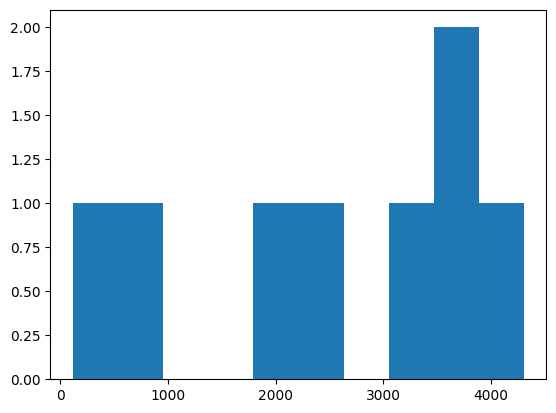

In [119]:
plt.hist(yb[0,:])

(array([2., 1., 1., 1., 0., 1., 0., 0., 0., 2.]),
 array([ 464. ,  831.8, 1199.6, 1567.4, 1935.2, 2303. , 2670.8, 3038.6,
        3406.4, 3774.2, 4142. ]),
 <BarContainer object of 10 artists>)

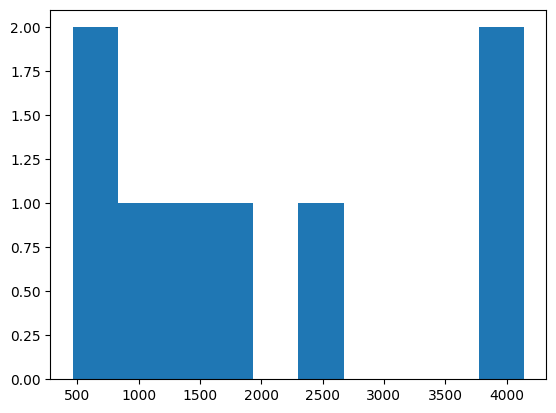

In [120]:
plt.hist(ybt[0,:])

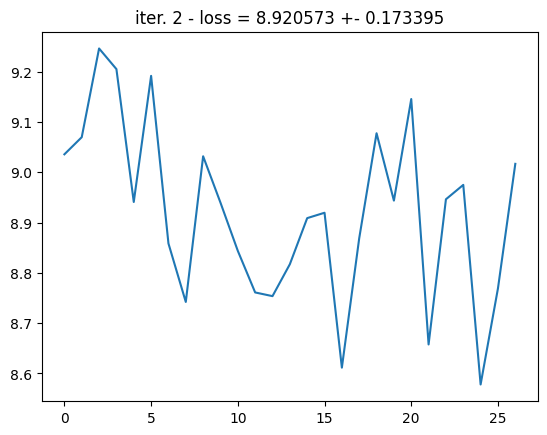

In [94]:
plt.plot(val_loss_list)
plt.title(f"iter. {epoch} - loss = {np.mean(val_loss_list):4f} +- {np.std(val_loss_list):4f}")
plt.show()

In [13]:
ybt.shape

torch.Size([32, 64])